In [35]:
import pandas as pd
import wfdb
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np
import wfdb.processing
from matplotlib.gridspec import GridSpec
import heartpy as hp
import os

In [53]:
fs = 100
record_id = 4
df_ecg_scp = pd.read_csv(r"C:\Users\bscuser\Desktop\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.2\ptbxl_database.csv")
column_names = ['SCP_Code', 'Description', 'Unused1', 'Unused2', 'Unused3', 'diagnosis_class', 'diagnosis_subclass', 'Unused6', 'SCP-ECG_Statement_Description', 'Unused8', 'Unused9', 'Unused10', 'Unused11']
df_scp_description = pd.read_csv(r"C:\Users\bscuser\Desktop\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.2\scp_statements.csv",
                                 header=None,
                                 skiprows=1,
                                 names=column_names)
df_scp_description = df_scp_description[['SCP_Code', 'Description', 'diagnosis_class', 'diagnosis_subclass', 'SCP-ECG_Statement_Description']]
df_ecg_scp['scp_codes'] = df_ecg_scp['scp_codes'].apply(eval)

exploded_rows = []
for idx, row in df_ecg_scp.iterrows():
    ecg_id = row['ecg_id']
    scp_codes = row['scp_codes']
    for code, percentage in scp_codes.items():
        exploded_rows.append({'ecg_id': ecg_id, 'scp_code': code, 'Percentage': percentage})

df_exploded = pd.DataFrame(exploded_rows)
df_merged = pd.merge(df_exploded, df_scp_description, left_on='scp_code', right_on='SCP_Code', how='left')


In [54]:
#Read ECG signal 

def read_ecg(record_id):
    base = r"C:\Users\bscuser\Desktop\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.2"
    record_path = f"{base}/records100/{str(record_id).zfill(5)[:3]}00/{str(record_id).zfill(5)}_lr"
    record = wfdb.rdrecord(record_path)
    signals = record.p_signal
    return signals, record.fs, record.sig_name, record_path

In [55]:
#Plot 12lead ECG with some annotation such as diagnosis and sex and Age which could be modiefied based on the needs

def plot_ecg_with_annotations(ecg_id, ecg_signal, annotations, sig_names):
    num_leads = ecg_signal.shape[1]
    num_rows = (num_leads + 1) // 2  # Calculate the number of rows needed for 2 columns
    time_axis = np.arange(ecg_signal.shape[0]) / 100
    fig = plt.figure(figsize=(15, 3 * num_rows + 2))
    gs = GridSpec(num_rows + 1, 2, figure=fig, height_ratios=[1] + [1] * num_rows)  

    ax_annotation = fig.add_subplot(gs[0, :])
    ax_annotation.axis('off')  

    annotation_text = f"Patient ID: {patient_info['patient_id']}, Age: {patient_info['age']}, Sex: {'Female' if patient_info['sex'] == 1 else 'Male'}\n"
    for idx, annotation in enumerate(annotations):
        scp_code = annotation['SCP_Code']
        percentage = annotation['Percentage']
        description = annotation['Description']
        diagnosis_class = annotation['diagnosis_class']
        subdiagnosis_class = annotation['diagnosis_subclass']
        if pd.notna(diagnosis_class) and pd.notna(subdiagnosis_class):
            annotation_text += f"{scp_code}: {description} ({percentage}%), Diagnosis: {diagnosis_class}, Subdiagnosis: {subdiagnosis_class}\n"
        else:
            annotation_text += f"{scp_code}: {description} ({percentage}%)\n"
    ax_annotation.text(0.5, 0.5, annotation_text, horizontalalignment='center', verticalalignment='center', fontsize=11,
                       bbox=dict(facecolor='white', alpha=0.5))

    # Create the ECG lead plots
    for i in range(num_leads):
        ax = fig.add_subplot(gs[i // 2 + 1, i % 2])
        ax.plot(time_axis,ecg_signal[:, i])
        ax.text(0.95, 0.95, f'Lead: {sig_names[i]}', horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes, fontsize=7, bbox=dict(facecolor='white', alpha=0.5))

        if i % 2 == 0:  
            ax.set_ylabel('Amplitude(μV)')
        else:
            ax.set_yticklabels([])  

        if i // 2 == num_rows - 1: 
            ax.set_xlabel('Time(sec)')
        else:
            ax.set_xticklabels([])  

    if num_leads % 2 != 0:
        fig.delaxes(fig.add_subplot(gs[-1, -1]))

    plt.subplots_adjust(hspace=0.5)  
    plt.tight_layout()
    plt.show()

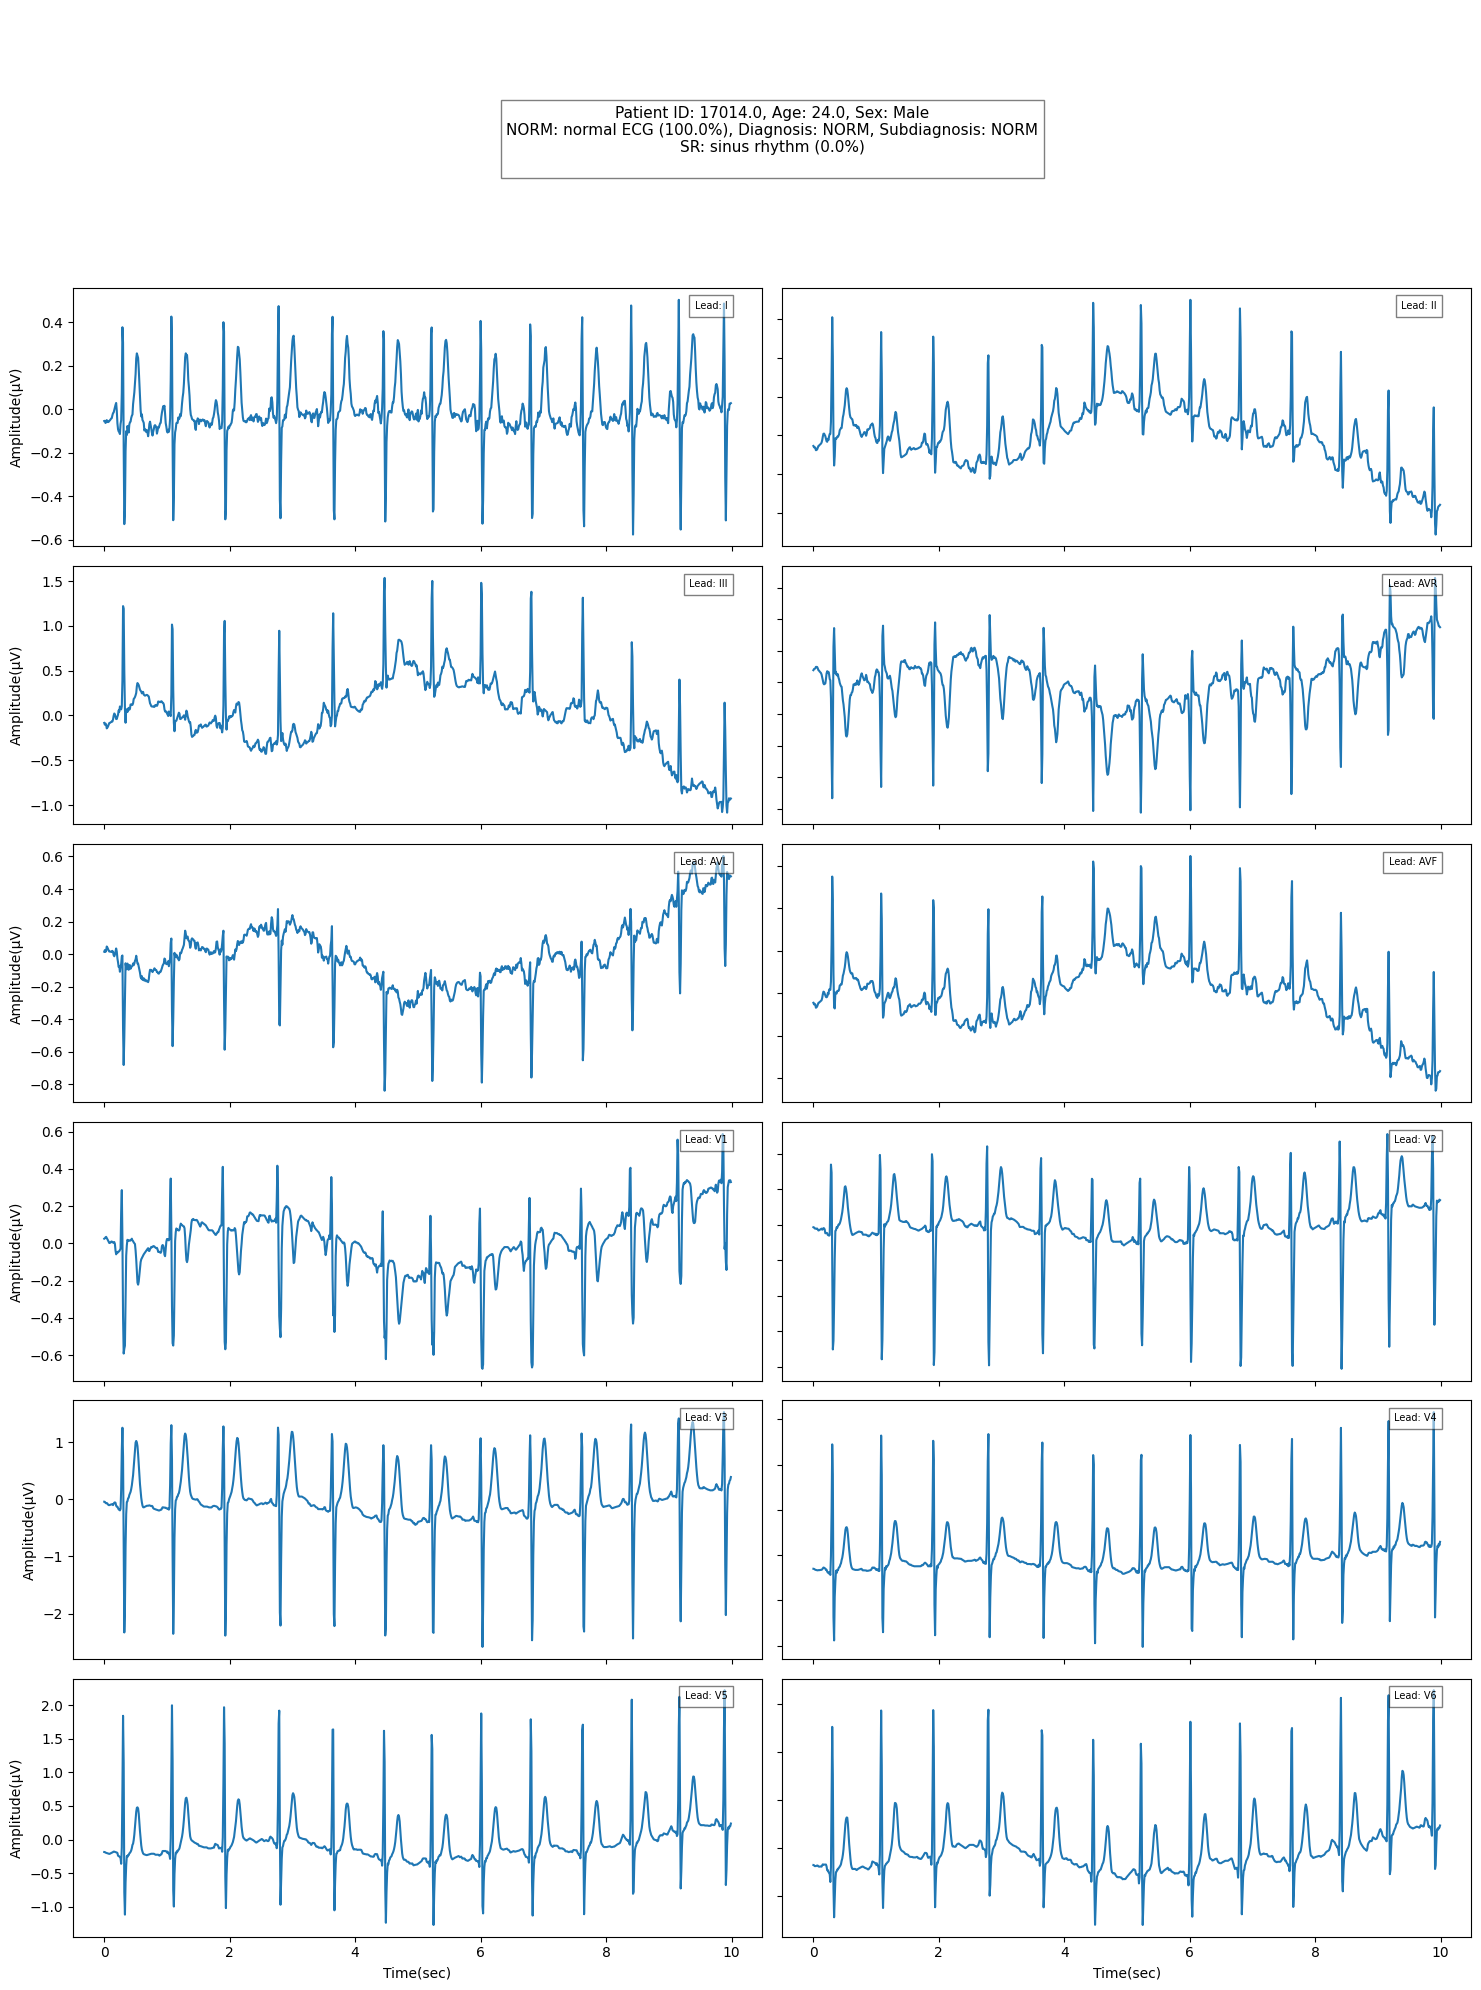

In [57]:
#plotting one signal as an example

record_id = 4
signals, fs, sig_name,record_path = read_ecg(record_id)
patient_info = df_ecg_scp[df_ecg_scp['ecg_id'] == record_id][['patient_id', 'age', 'sex']].iloc[0].to_dict()
annotations = df_merged[df_merged['ecg_id'] == ecg_id].to_dict('records')
plot_ecg_with_annotations(ecg_id, signals, annotations,sig_name)

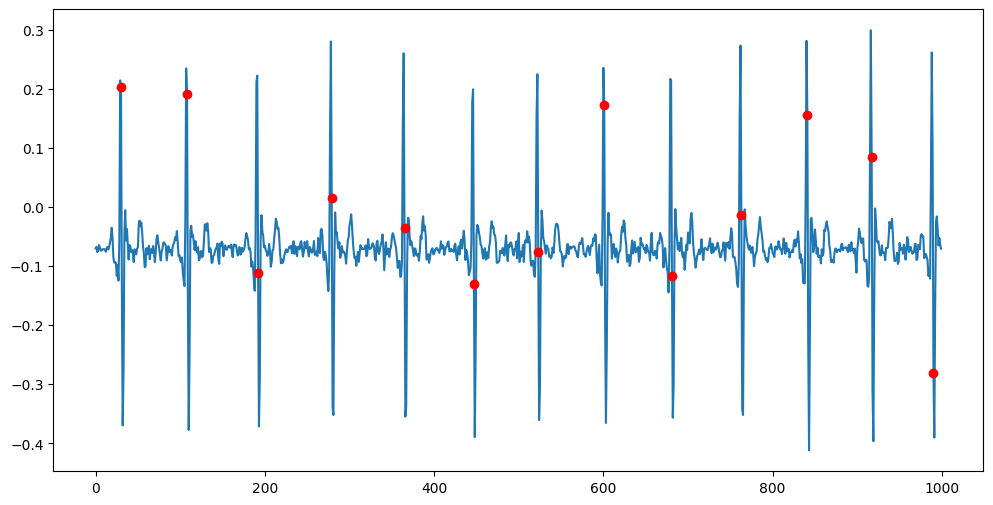

In [58]:
#Removing baseline noise and extracting R-peaks 
# R-peaks are already extracted into the annotation file so it is just mapped on teh signal but manual r-peak extraction also could be used.

filtered_signal = hp.remove_baseline_wander(signals[:,0], sample_rate=100, cutoff=0.05)
r_peaks_str = df_ecg_scp[df_ecg_scp['ecg_id'] == record_id]['r_peaks'].iloc[0]
r_peaks=r_peaks_str.strip('[]').strip()
r_peaks = [int(x) for x in r_peaks.split()]
plt.figure(figsize=(12, 6))
plt.plot(filtered_signal, label='Filtered ECG Signal (Lead 1)')
plt.plot(r_peaks, filtered_signal[r_peaks], 'ro', label='R-peaks (valid)')
plt.show()


In [61]:
#Calculating the heart beat and heart beat based on R-peaks

num_beats = len(r_peaks)
print("Numebr of Beats in 10 Seconds signals is:",num_beats,"Beats" )
duration = len(signals) / fs  
heart_rate = num_beats / duration * 60  
print("The Heart Rate (HR) is:", heart_rate, "BPM" )
rr_intervals = np.diff(r_peaks) / fs
average_heart_rate = 60 / np.mean(rr_intervals)
print("Average Heart Rate:", average_heart_rate, "BPM")


Numebr of Beats in 10 Seconds signals is: 13 Beats
The Heart Rate (HR) is: 78.0 BPM
Average Heart Rate: 75.0 BPM


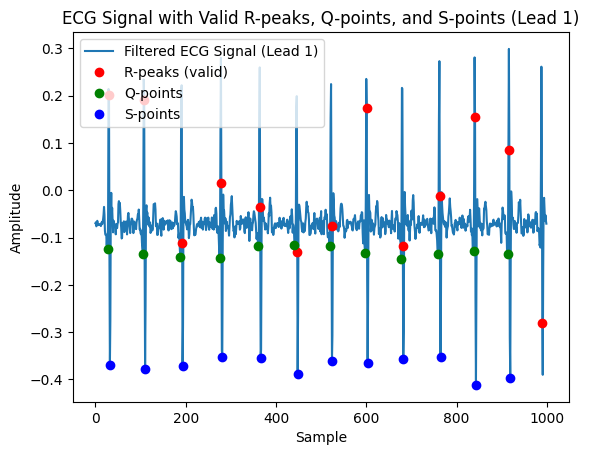

In [62]:
#Defining Q and S points based on the R-peaks 

def find_q_s_points(sig, rpeaks, search_radius=30):
    q_points = []
    s_points = []

    for rpeak in rpeaks:
        if rpeak - search_radius < 0 or rpeak + search_radius >= len(sig):
            continue

        # Q-point is the minimum point in the interval [rpeak - search_radius, rpeak)
        q_interval = sig[max(0, rpeak - search_radius):rpeak]
        q_point = q_interval.argmin() + max(0, rpeak - search_radius)
        q_points.append(q_point)

        # S-point is the minimum point in the interval (rpeak, rpeak + search_radius]
        s_interval = sig[rpeak:min(len(sig), rpeak + search_radius)]
        s_point = s_interval.argmin() + rpeak
        s_points.append(s_point)

    return q_points, s_points
    

q_points, s_points = find_q_s_points(filtered_signal, r_peaks)
plt.plot(filtered_signal, label='Filtered ECG Signal (Lead 1)')
plt.plot(r_peaks, filtered_signal[r_peaks], 'ro', label='R-peaks (valid)')
plt.plot(q_points, filtered_signal[q_points], 'go', label='Q-points')
plt.plot(s_points, filtered_signal[s_points], 'bo', label='S-points')
plt.title('ECG Signal with Valid R-peaks, Q-points, and S-points (Lead 1)')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

0.2461183771145875
[29, 107, 107, 191, 191, 278, 278, 364, 364, 446, 446, 522, 522, 600, 600, 679, 679, 762, 762, 840, 840, 916, 916, 988]


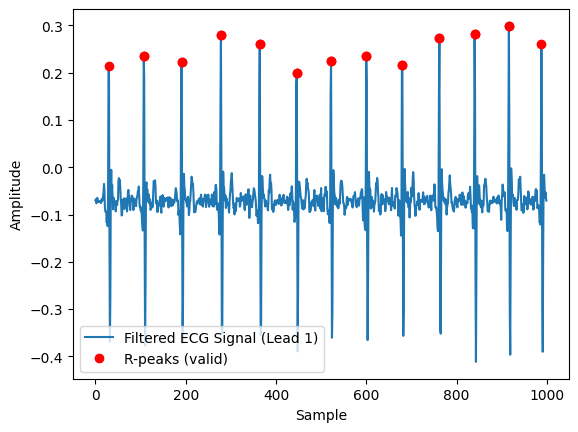

In [71]:
# optional:for some cases such as record_id = 4 the rpeaks in the annotation file is not accurate and we can use manual rpeaks extraction models.
rpeaks = wfdb.processing.xqrs_detect(sig=filtered_signal, fs=fs, verbose=False)
if len(rpeaks) == 0:
    print("No R-peaks detected. Adjusting parameters or finding manually.")
    rpeaks, _ = find_peaks(filtered_signal, distance=fs * 0.6,
                           height=filtered_signal.mean() + 0.5 * filtered_signal.std())
rpeaks_corrected = wfdb.processing.correct_peaks(sig=filtered_signal, peak_inds=rpeaks, search_radius=36,
                                                 smooth_window_size=50, peak_dir='up')
avg_height = filtered_signal[rpeaks_corrected[1:-1]].mean()
print(avg_height)
rpeaks_corrected = [peak for peak in rpeaks_corrected if peak >= 0] #discard negative indexes
rpeaks_corrected = [peak for peak in rpeaks_corrected if filtered_signal[peak] >= avg_height*0.75]
print(rpeaks_corrected)
plt.plot(filtered_signal, label='Filtered ECG Signal (Lead 1)')
plt.plot(rpeaks_corrected, filtered_signal[rpeaks_corrected], 'ro', label='R-peaks (valid)')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

1
{'patient_id': 15709.0, 'age': 56.0, 'sex': 1.0}


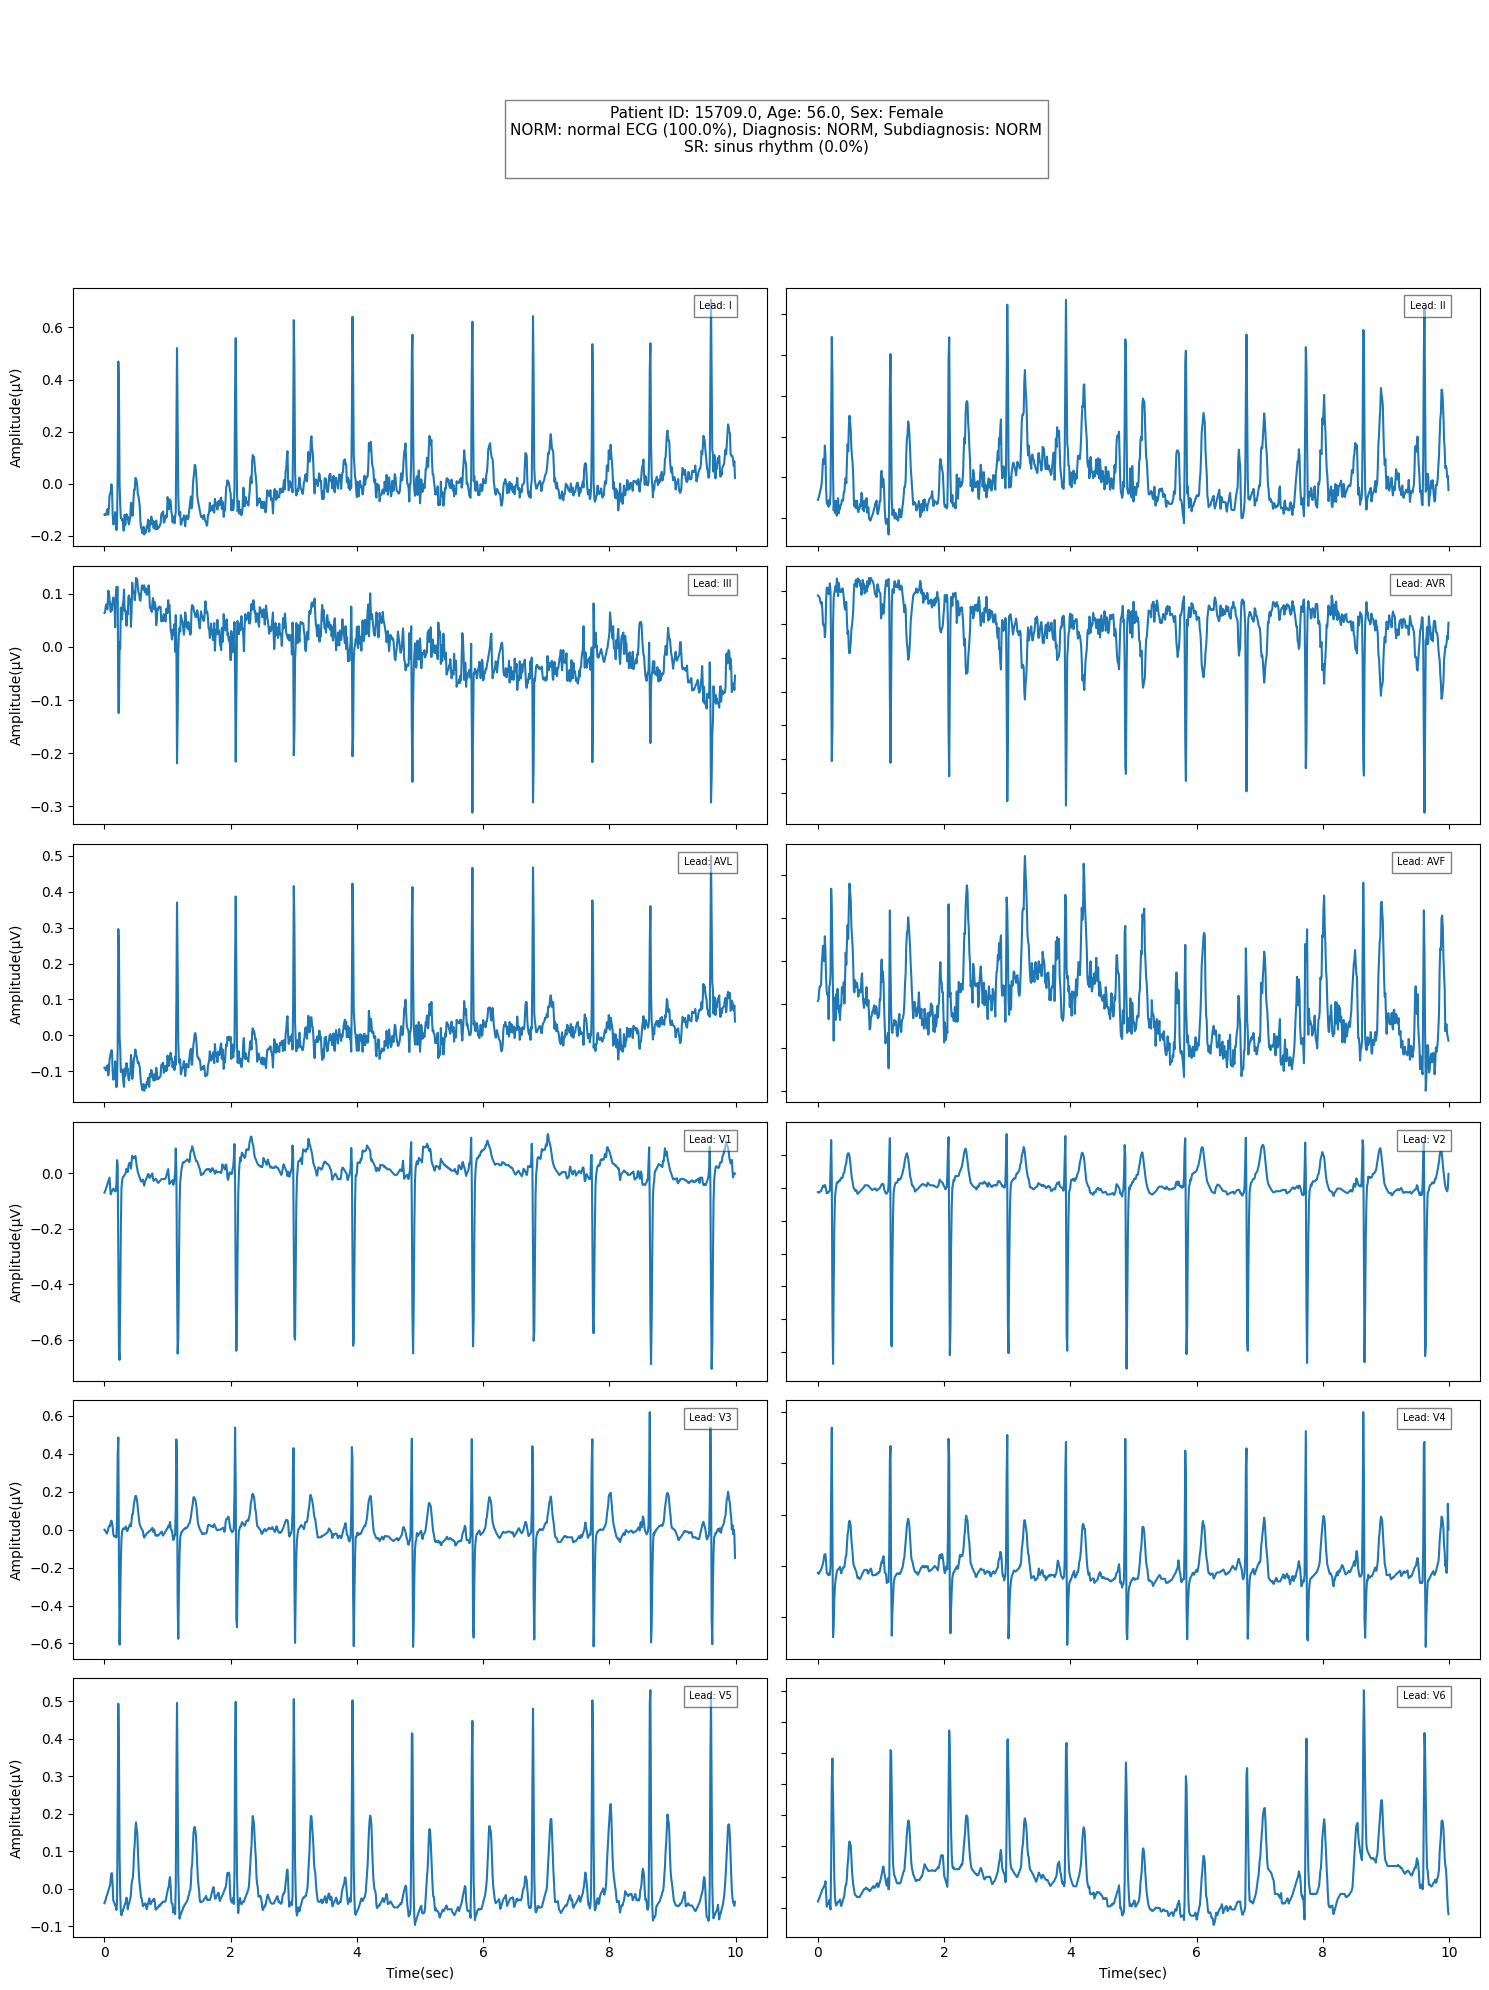

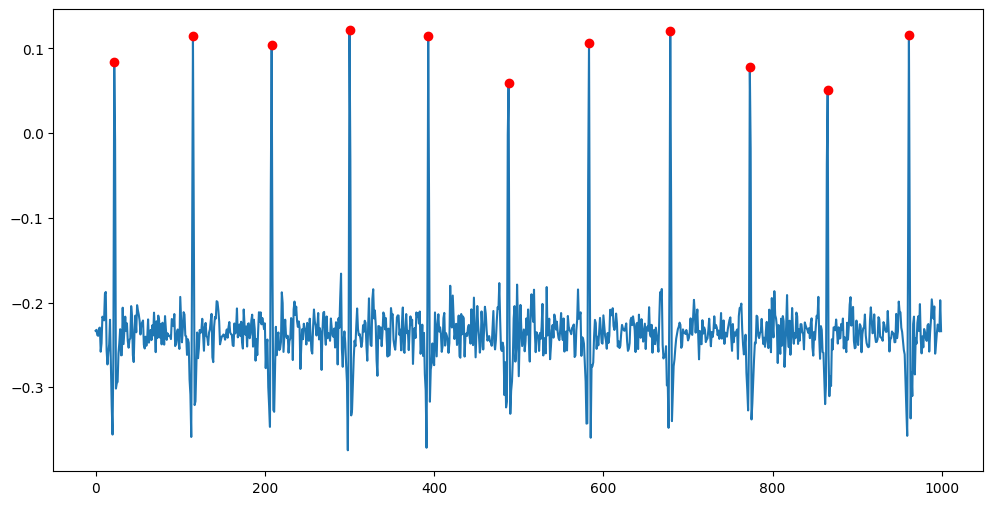

Numebr of Beats in 10 Seconds signals is: 11 Beats
The Heart Rate (HR) is: 66.0 BPM
Average Heart Rate: 63.897763578274756 BPM


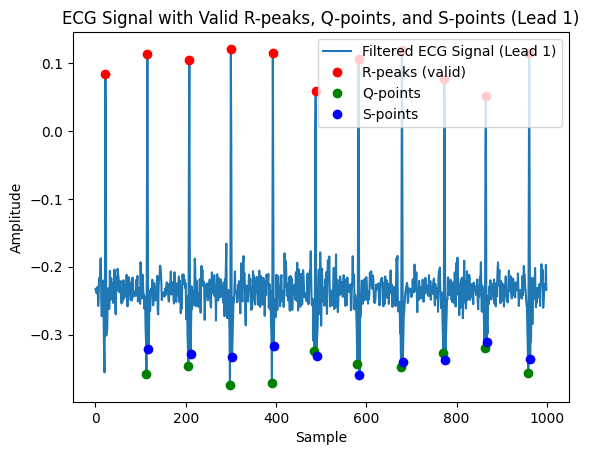

2
{'patient_id': 13243.0, 'age': 19.0, 'sex': 0.0}


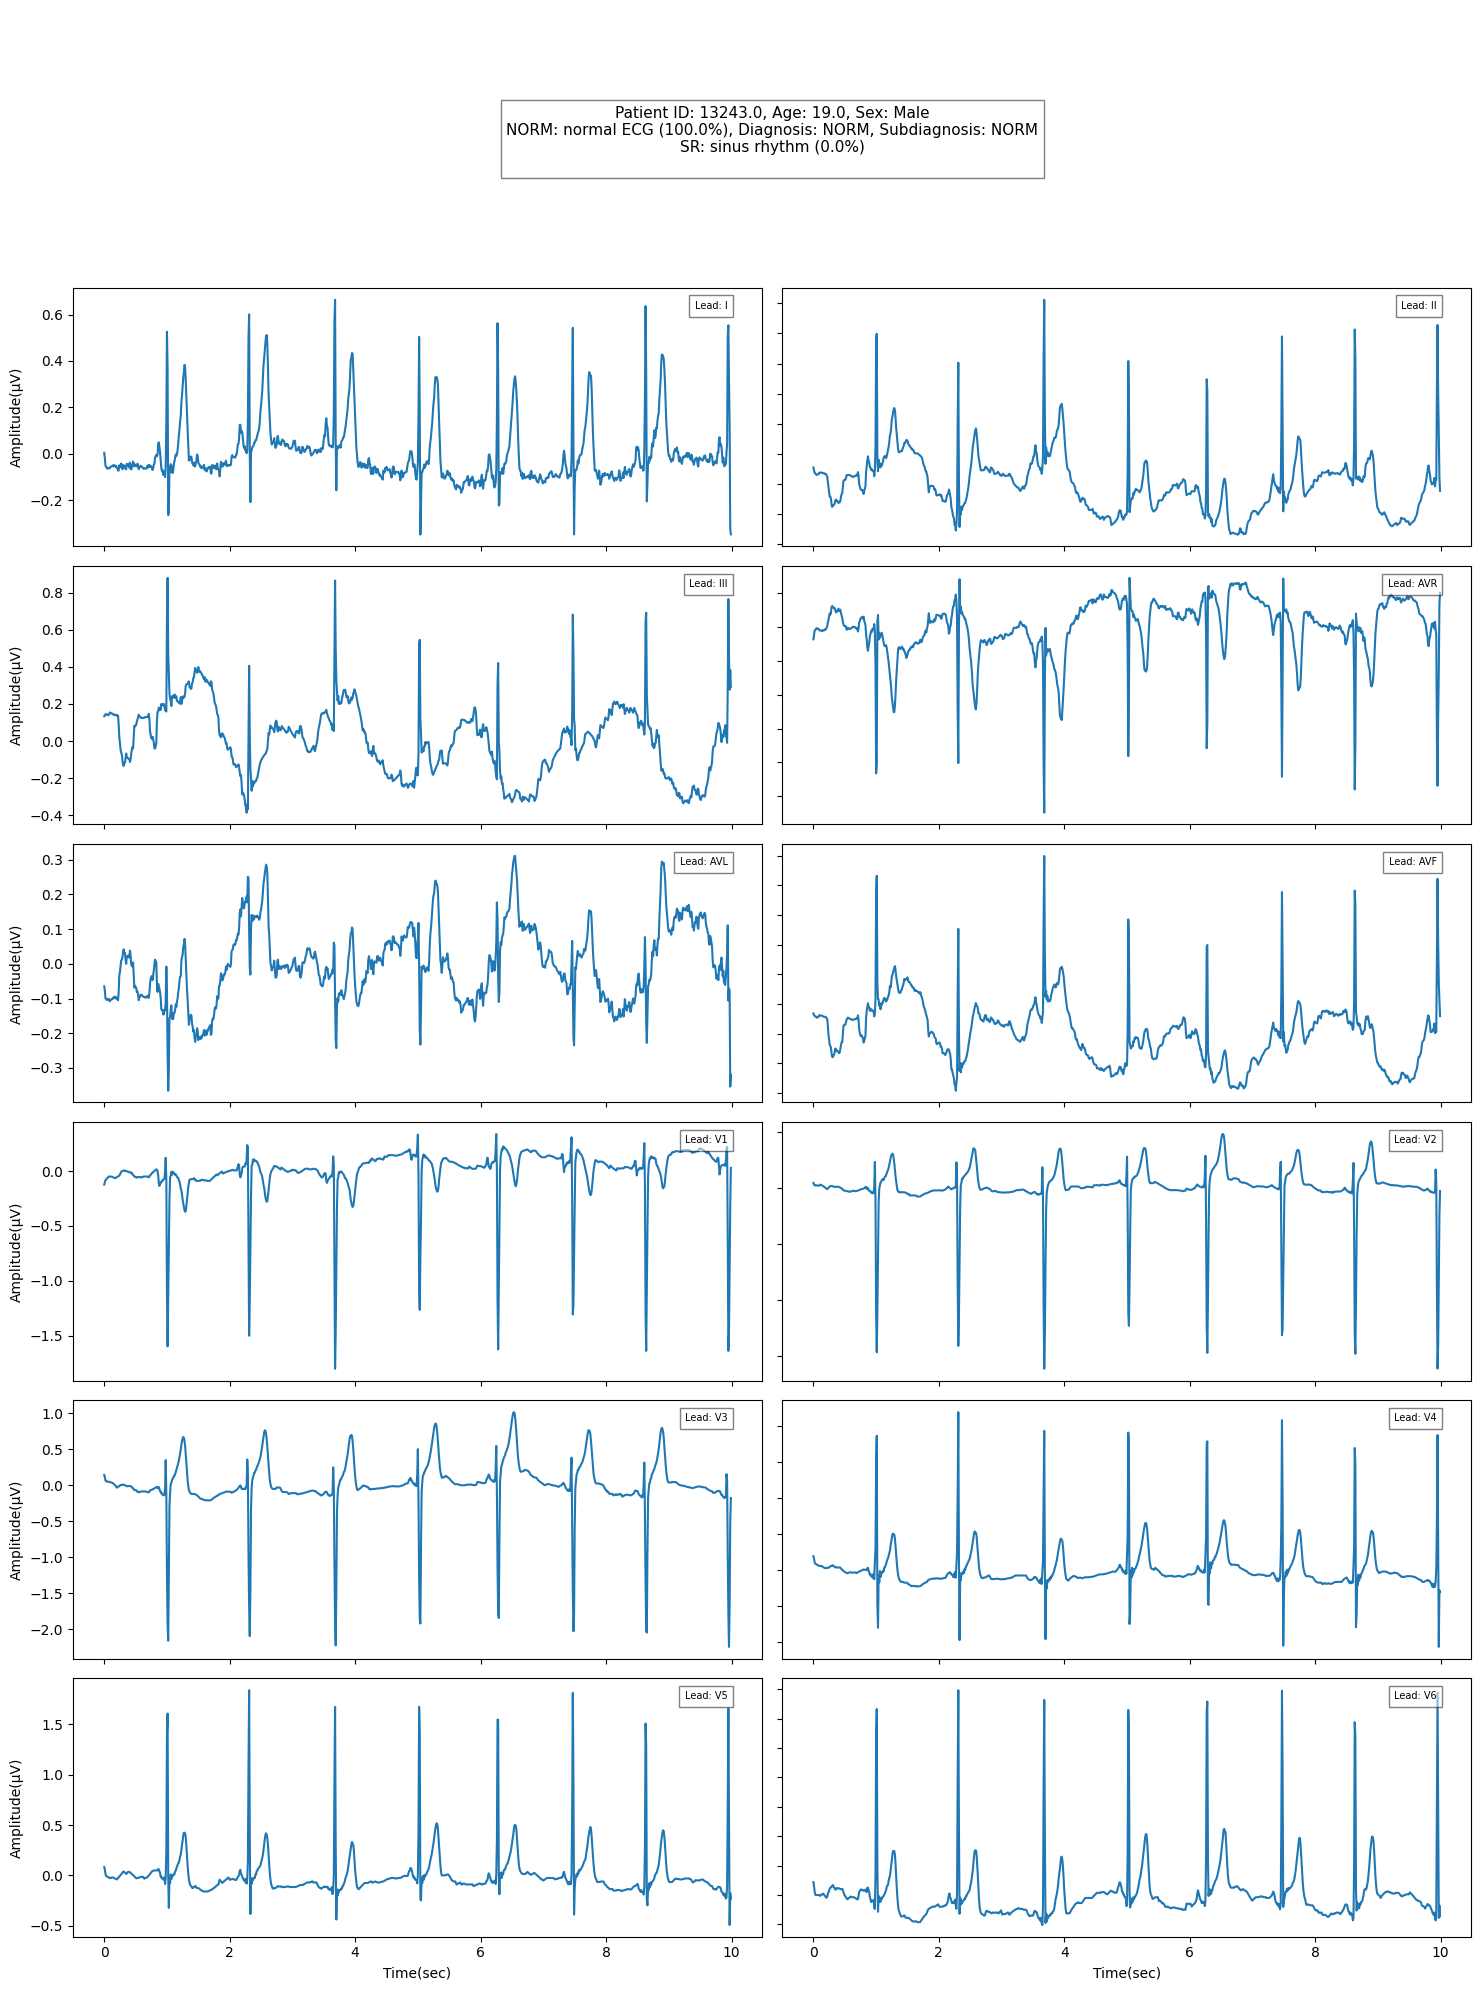

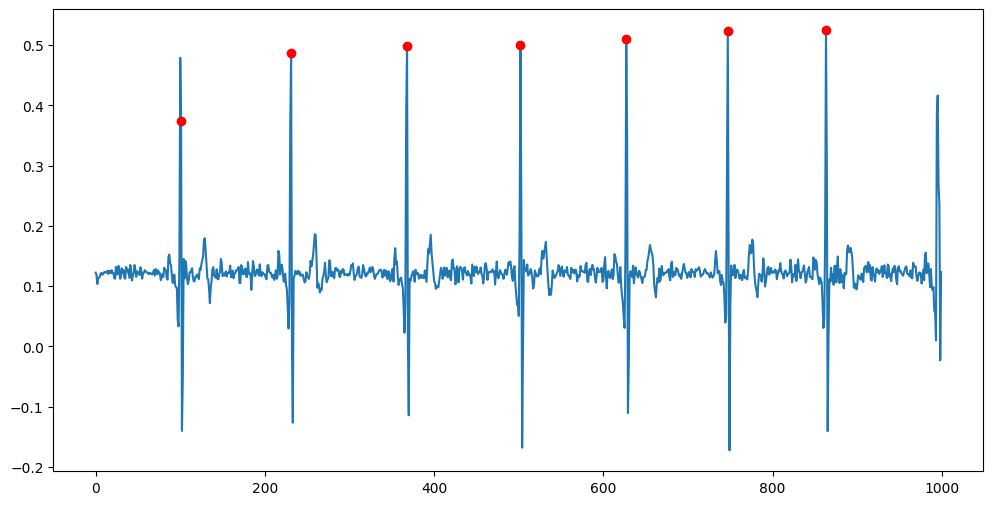

Numebr of Beats in 10 Seconds signals is: 7 Beats
The Heart Rate (HR) is: 42.0 BPM
Average Heart Rate: 47.24409448818898 BPM


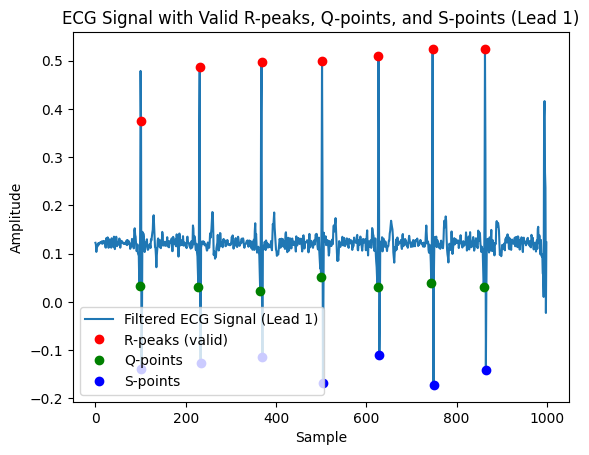

3
{'patient_id': 20372.0, 'age': 37.0, 'sex': 1.0}


KeyboardInterrupt: 

In [79]:
## optional: to loop over all the files , read them and apply all above functions

def read_ecg(record_id, base_path):
    record_folder = f"{str(record_id)[:2]}000"
    record_path = f"{base}/records100/{str(record_id).zfill(5)[:2]}000/{str(record_id).zfill(5)}_lr"
    record = wfdb.rdrecord(record_path)
    signals = record.p_signal
    return signals, record.fs, record.sig_name, record_path

def plot_ecg_with_annotations(ecg_id, ecg_signal, annotations, sig_names, patient_info):
    num_leads = ecg_signal.shape[1]
    num_rows = (num_leads + 1) // 2  # Calculate the number of rows needed for 2 columns
    time_axis = np.arange(ecg_signal.shape[0]) / 100
    fig = plt.figure(figsize=(15, 3 * num_rows + 2))
    gs = GridSpec(num_rows + 1, 2, figure=fig, height_ratios=[1] + [1] * num_rows)  

    ax_annotation = fig.add_subplot(gs[0, :])
    ax_annotation.axis('off')  

    # Dynamic annotation text based on patient_info
    annotation_text = f"Patient ID: {patient_info['patient_id']}, Age: {patient_info['age']}, Sex: {'Female' if patient_info['sex'] == 1 else 'Male'}\n"

    # Loop over annotations for the current ECG record
    for idx, annotation in enumerate(annotations):
        scp_code = annotation['SCP_Code']
        percentage = annotation['Percentage']
        description = annotation['Description']
        diagnosis_class = annotation['diagnosis_class']
        subdiagnosis_class = annotation['diagnosis_subclass']
        if pd.notna(diagnosis_class) and pd.notna(subdiagnosis_class):
            annotation_text += f"{scp_code}: {description} ({percentage}%), Diagnosis: {diagnosis_class}, Subdiagnosis: {subdiagnosis_class}\n"
        else:
            annotation_text += f"{scp_code}: {description} ({percentage}%)\n"

    # Display the dynamic annotation text
    ax_annotation.text(0.5, 0.5, annotation_text, horizontalalignment='center', verticalalignment='center', fontsize=11,
                       bbox=dict(facecolor='white', alpha=0.5))

    # Create the ECG lead plots
    for i in range(num_leads):
        ax = fig.add_subplot(gs[i // 2 + 1, i % 2])
        ax.plot(time_axis, ecg_signal[:, i])
        ax.text(0.95, 0.95, f'Lead: {sig_names[i]}', horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes, fontsize=7, bbox=dict(facecolor='white', alpha=0.5))

        if i % 2 == 0:  
            ax.set_ylabel('Amplitude(μV)')
        else:
            ax.set_yticklabels([])  

        if i // 2 == num_rows - 1:  
            ax.set_xlabel('Time(sec)')
        else:
            ax.set_xticklabels([])  

    if num_leads % 2 != 0:
        fig.delaxes(fig.add_subplot(gs[-1, -1]))

    plt.subplots_adjust(hspace=0.5)  
    plt.tight_layout()
    plt.show()

# Example usage assuming you have multiple records

def process_multiple_ecgs(base_path, df_ecg_scp):
    for idx, row in df_ecg_scp.iterrows():
        record_id = row['ecg_id']
        patient_id = row['patient_id']
        filename_hr = row['filename_hr']
        filename_lr = row['filename_lr']
        
        # Read ECG signal
        print(record_id)
        signals, fs, sig_name, record_path = read_ecg(record_id, base_path)
        patient_info = df_ecg_scp[df_ecg_scp['ecg_id'] == record_id][['patient_id', 'age', 'sex']].iloc[0].to_dict()
        print(patient_info)
        annotations = df_merged[df_merged['ecg_id'] == ecg_id].to_dict('records')
        plot_ecg_with_annotations(ecg_id, signals, annotations, sig_name, patient_info)
        filtered_signal = hp.remove_baseline_wander(signals[:,0], sample_rate=100, cutoff=0.05)
        r_peaks_str = df_ecg_scp[df_ecg_scp['ecg_id'] == record_id]['r_peaks'].iloc[0]
        r_peaks=r_peaks_str.strip('[]').strip()
        r_peaks = [int(x) for x in r_peaks.split()]
        plt.figure(figsize=(12, 6))
        plt.plot(filtered_signal, label='Filtered ECG Signal (Lead 1)')
        plt.plot(r_peaks, filtered_signal[r_peaks], 'ro', label='R-peaks (valid)')
        plt.show()
        num_beats = len(r_peaks)
        print("Numebr of Beats in 10 Seconds signals is:",num_beats,"Beats" )
        duration = len(signals) / fs  
        heart_rate = num_beats / duration * 60  
        print("The Heart Rate (HR) is:", heart_rate, "BPM" )
        rr_intervals = np.diff(r_peaks) / fs
        average_heart_rate = 60 / np.mean(rr_intervals)
        print("Average Heart Rate:", average_heart_rate, "BPM")
        q_points, s_points = find_q_s_points(filtered_signal, r_peaks)
        plt.plot(filtered_signal, label='Filtered ECG Signal (Lead 1)')
        plt.plot(r_peaks, filtered_signal[r_peaks], 'ro', label='R-peaks (valid)')
        plt.plot(q_points, filtered_signal[q_points], 'go', label='Q-points')
        plt.plot(s_points, filtered_signal[s_points], 'bo', label='S-points')
        plt.title('ECG Signal with Valid R-peaks, Q-points, and S-points (Lead 1)')
        plt.xlabel('Sample')
        plt.ylabel('Amplitude')
        plt.legend()
        plt.show()
        
        
        
base = r"C:\Users\bscuser\Desktop\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.2"
process_multiple_ecgs(base_path, df_ecg_scp)

